# Model 01 · Will I study or open Instagram?
Binary classifier. Synthetic data with a hidden "discipline" trait, structural effects and label noise,
so the model has something real to learn and a ceiling it cannot beat.

**Flow:** generate data → EDA → features → train/validate → test → importance → export JSON → verify.

In [1]:
import sys
sys.path.insert(0, "../_shared")
try:
    import kit
except ImportError:
    from google.colab import files; files.upload(); import kit
from kit import *
rng_seed = SEED

## 1 · Dataset generator
Every effect has a sign you can defend in a bar. Nothing is deterministic: a hidden trait plus logit noise.

In [2]:
APPS = ["studying", "scrolling", "watching", "eating", "chatting", "nothing"]
ACT_EFFECT = {"studying": 1.0, "scrolling": -0.9, "watching": -0.5, "eating": 0.0, "chatting": -0.3, "nothing": 0.1}

def generate(n=10000, seed=SEED):
    r = np.random.default_rng(seed)
    d = pd.DataFrame({
        "hour": (r.uniform(8, 27, n)) % 24,
        "battery": np.clip(r.beta(2.2, 1.6, n) * 100, 1, 100),
        "sleep": np.clip(r.normal(6.6, 1.5, n), 2, 11),
        "deadline_hours": np.clip(np.exp(r.normal(3.6, 1.4, n)), 0.5, 720),
        "phone_distance": r.choice([0, 1, 2, 3], n, p=[.35, .35, .2, .1]),
        "mood": r.choice([0, 1, 2, 3], n, p=[.2, .35, .3, .15]),
        "tabs": np.clip(r.poisson(9, n), 0, 60),
        "last_activity": r.choice(APPS, n, p=[.15, .3, .15, .12, .18, .10]),
    })
    disc = r.normal(0, 1, n)
    late = ((d.hour >= 23) | (d.hour < 5)).astype(float)
    logit = (-1.25 + 0.8 * disc + 0.22 * (d.sleep - 6.5) + 0.38 * (d.mood - 1.5) + 0.55 * (d.phone_distance - 1.2)
             + 1.8 * np.exp(-d.deadline_hours / 30) - 0.03 * d.tabs - 0.9 * late
             - 0.2 * ((d.hour >= 14) & (d.hour < 17)) + 0.35 * (d.battery < 15) + d.last_activity.map(ACT_EFFECT)
             - 0.8 * late * (d.phone_distance <= 1) + 0.5 * ((d.mood >= 2) & (d.deadline_hours < 24)))
    d["study"] = (r.random(n) < sigmoid(logit + r.normal(0, 0.5, n))).astype(int)
    d["p_true"] = sigmoid(logit)
    return d

In [3]:
df = generate(10000)
df.drop(columns="p_true").to_csv("dataset.csv", index=False)
print(df.shape, "| study rate:", round(df.study.mean(), 3))
df.drop(columns="p_true").head()

(10000, 10) | study rate: 0.265


,hour,battery,sleep,deadline_hours,phone_distance,mood,tabs,last_activity,study
0,22.705165,8.636110,7.481755,17.483071,0,3,5,watching,1
1,16.338690,63.165595,7.213756,3.523648,1,1,11,eating,0
2,0.313360,95.908372,7.342736,11.781386,0,1,8,scrolling,0
3,21.249993,70.473927,5.747440,179.869073,3,3,10,scrolling,0
4,9.789370,58.242894,3.614775,59.577931,2,2,9,nothing,0


## 2 · Cleaning + EDA

In [4]:
print("nulls:", int(df.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()))
df.drop(columns="p_true").describe().T.round(2)

nulls: 0 | duplicates: 0


,count,mean,std,min,25%,50%,75%,max
hour,10000.0,13.72,6.74,0.0,9.82,14.48,19.24,24.00
battery,10000.0,57.35,22.90,1.0,40.09,59.09,75.92,99.89
sleep,10000.0,6.59,1.50,2.0,5.60,6.59,7.59,11.00
deadline_hours,10000.0,87.62,135.81,0.5,14.26,36.65,95.53,720.00
phone_distance,10000.0,1.05,0.97,0.0,0.00,1.00,2.00,3.00
mood,10000.0,1.40,0.97,0.0,1.00,1.00,2.00,3.00
tabs,10000.0,8.99,3.00,0.0,7.00,9.00,11.00,22.00
study,10000.0,0.27,0.44,0.0,0.00,0.00,1.00,1.00


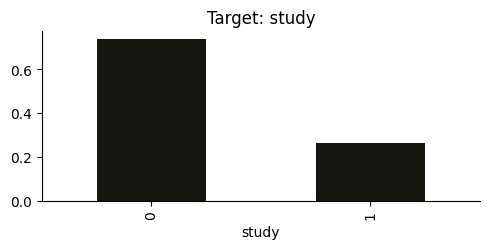

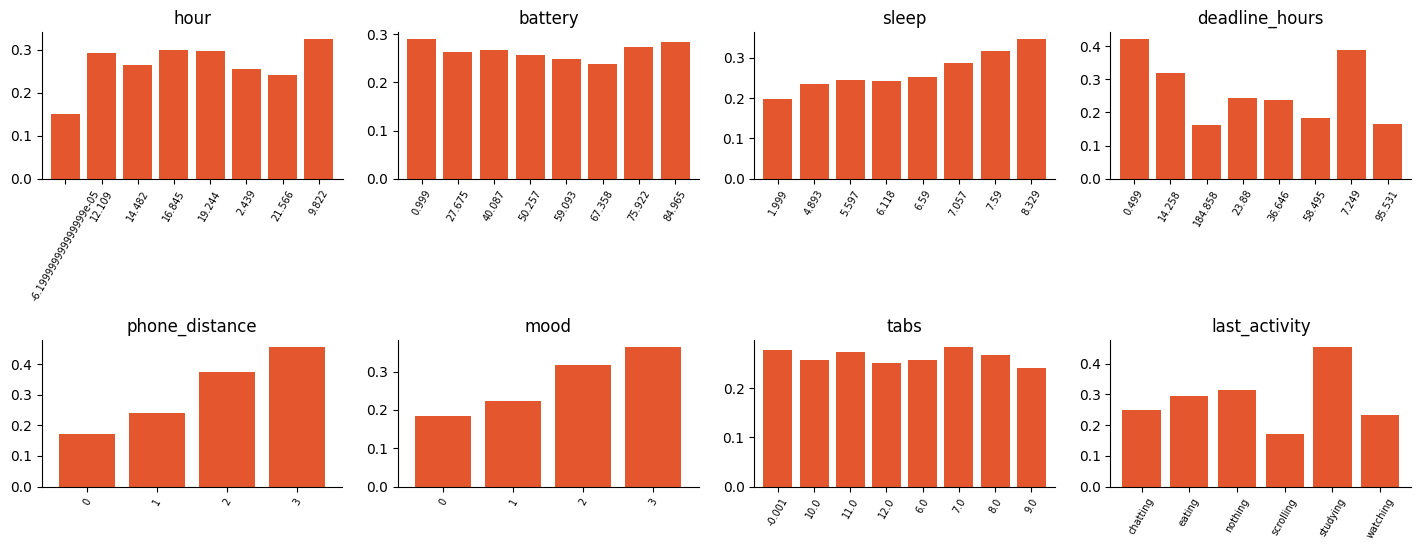

In [5]:
INPUTS = [Num("hour", 0, 24, "cyc"), Num("battery", 0, 100), Num("sleep", 0, 14), Num("deadline_hours", 0, 720, "log1p"),
          Num("phone_distance", 0, 3), Num("mood", 0, 3), Num("tabs", 0, 60), Cat("last_activity", APPS)]
RAW = [s["name"] for s in INPUTS]
eda(df, "study", RAW, "binary")

## 3 · Features + split
Hour becomes sin/cos, deadline becomes log1p, activity is one-hot. The same recipe is exported and used on the website.

In [6]:
fz = Featurizer(INPUTS)
tr, va, te = split3(df, "study")
Xtr, Xva, Xte = fz.transform(tr), fz.transform(va), fz.transform(te)
print(Xtr.shape, Xva.shape, Xte.shape, fz.names)

(7000, 14) (1500, 14) (1500, 14) ['hour_sin', 'hour_cos', 'battery', 'sleep', 'deadline_hours_log1p', 'phone_distance', 'mood', 'tabs', 'last_activity=studying', 'last_activity=scrolling', 'last_activity=watching', 'last_activity=eating', 'last_activity=chatting', 'last_activity=nothing']


## 4 · Train + select (validation log-loss)

In [7]:
best, best_name, table = train_classifier(Xtr, tr.study, Xva, va.study, depth=8, leaf=25)
print("selected:", best_name); table.round(4)

selected:

 Logistic Regression


,model,val_log_loss,val_accuracy
0,Logistic Regression,0.4814,0.7733
1,Random Forest (isotonic-calibrated),0.5048,0.7660


## 5 · Test-set evaluation

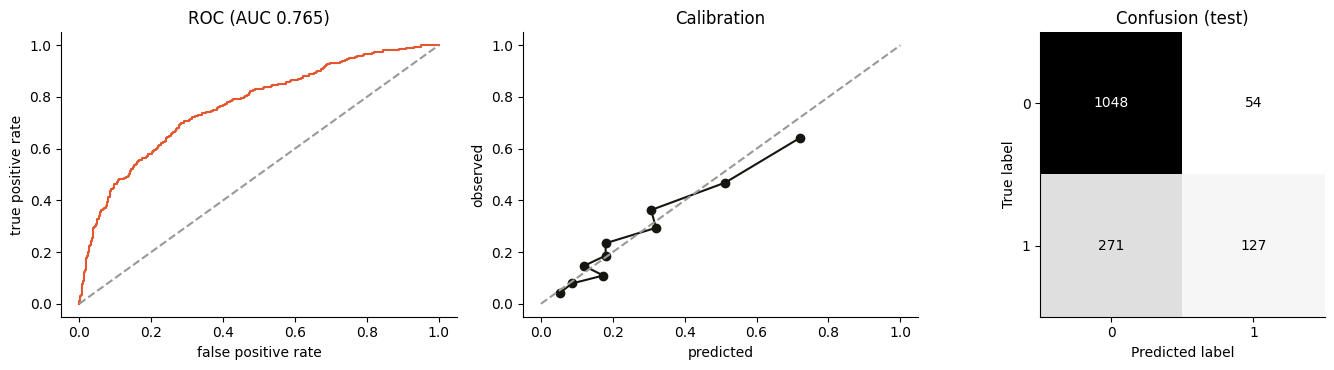

{'accuracy': 0.7833,
 'roc_auc': 0.7655,
 'log_loss': 0.4852,
 'brier': 0.1575,
 'oracle_auc': 0.8114}

In [8]:
m = report_binary(best, Xte, te.study)
m["oracle_auc"] = round(float(roc_auc_score(te.study, te.p_true)), 4)
m

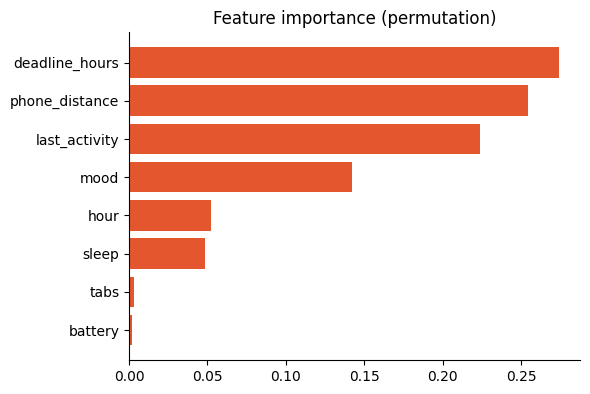

{'deadline_hours': 0.2739,
 'phone_distance': 0.2543,
 'last_activity': 0.2236,
 'mood': 0.1422,
 'hour': 0.0526,
 'sleep': 0.0484,
 'tabs': 0.0032,
 'battery': 0.0018}

In [9]:
imp = group_importance(lambda X: best.predict_proba(X)[:, 1], Xte, te.study.to_numpy(), fz.groups,
                       lambda y, p: log_loss(y, p))
plot_importance(imp); imp

## 6 · Example predictions

In [10]:
ex = pd.DataFrame([
    dict(hour=23.5, battery=34, sleep=5.2, deadline_hours=90, phone_distance=0, mood=0, tabs=22, last_activity="scrolling"),
    dict(hour=10, battery=80, sleep=8, deadline_hours=4, phone_distance=3, mood=3, tabs=5, last_activity="studying")])
ex["P(study)"] = best.predict_proba(fz.transform(ex))[:, 1].round(3); ex

,hour,battery,sleep,deadline_hours,phone_distance,mood,tabs,last_activity,P(study)
0,23.5,34,5.2,90,0,0,22,scrolling,0.015
1,10.0,80,8.0,4,3,3,5,studying,0.937


## 7 · Export + verify
JSON out, then a pure-Python re-implementation of the website code must match sklearn.

In [11]:
head = export_head(best, labels=["instagram", "study"])
meta = make_metadata("v1.0", SEED, len(df), {"train": len(tr), "val": len(va), "test": len(te)},
    {"study": {"algorithm": best_name, "task": "binary", "metrics": m, "candidates": table.round(4).to_dict("records")}},
    imp, ["Synthetic data: metrics measure how well the model recovers the generator, not real people.",
          "Hidden discipline trait and label noise cap achievable accuracy; see oracle_auc."], "generate() in train.ipynb")
write_artifacts("model", "study-vs-instagram", "Will I study or open Instagram?", fz, tr, {"study": head}, {"study": best},
                meta, te[RAW])

wrote model (48 KB total) | export error vs sklearn: {'study': 1.1609233019349574e-09}


{'study': 1.1609233019349574e-09}